# Natural Language Processing — Lab 04
## Text Normalization, Cleaning & Minimum Edit Distance

| | |
|---|---|
| **Student** | Eman Amjad |
| **Roll Number** | FA23-BAI-013 |
| **Course** | Natural Language Processing |

This lab builds a reusable text-cleaning pipeline (lowercasing, punctuation and whitespace removal, stop-word removal, stemming and lemmatization) and implements Minimum Edit Distance, which is then used as a simple spelling corrector for customer-support chats.

In [1]:
# Setup  |  Eman Amjad  |  FA23-BAI-013
import re
import string
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import spacy
from IPython.display import display

for pkg in ["stopwords", "words", "brown", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)

from nltk.corpus import stopwords, words, brown
from nltk.stem import PorterStemmer
from nltk.sentiment import SentimentIntensityAnalyzer

nlp = spacy.load("en_core_web_sm")

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 140)

# Reference English lexicon used later to decide whether a string is a "real word":
# the NLTK word list (dictionary headwords) plus every word form seen in the Brown corpus
# (which adds inflected forms such as "charged" or "settings").
english_lexicon = {w.lower() for w in words.words()} | {w.lower() for w in brown.words() if w.isalpha()}

print(f"spaCy {spacy.__version__} | NLTK {nltk.__version__} | pandas {pd.__version__}")
print(f"Reference English lexicon: {len(english_lexicon):,} word forms")

spaCy 3.8.7 | NLTK 3.10.4 | pandas 3.1.0
Reference English lexicon: 251,972 word forms


### Datasets

The manual reads `reviews.csv` (columns `review_id`, `text`, ten product reviews) and a `support_chats` dataset of customer messages containing typos such as *pakage*, *arived*, *chek* and *beleive*. Neither file came with the manual, so the cell below writes both to `data/lab04/` and every activity then loads them from disk exactly as described. The reviews mix capitals, repeated punctuation, tabs and double spaces, and several of them depend on negation for their meaning; the chats mix spelling mistakes with informal chat language.

In [2]:
# Data preparation  |  Eman Amjad  |  FA23-BAI-013
DATA_DIR = Path("data/lab04")
DATA_DIR.mkdir(parents=True, exist_ok=True)

reviews = [
    "This phone is AMAZING!!! The camera quality is excellent and the battery lasts all day.",
    "Terrible experience.   The delivery was late, the box was damaged, and the item didn't work.",
    "The headphones are okay... not bad, but not great either.",
    "Honestly, the battery life is really impressive -- although the charger feels cheap and nothing else came in the box.",
    "I would never buy this again! The screen cracked after two weeks and customer service was no help at all.",
    "Running shoes fit perfectly; I've been running 5km every morning and my feet don't hurt anymore.",
    "Worst purchase ever.\tThe blender stopped working after three uses and the blades were already rusting.",
    "Good value for money. The studies I read online were right: these batteries are better than the cheaper brands.",
    "The laptop is fast, but it isn't worth the price. Fans get loud while gaming and the keys feel wobbly.",
    "Absolutely love it!!   My kids are happily playing with it every day, and it arrived earlier than expected.",
]
pd.DataFrame({"review_id": range(1, len(reviews) + 1), "text": reviews}).to_csv(
    DATA_DIR / "reviews.csv", index=False)

support_chats = [
    "Hi, my pakage still hasnt arived and its been 9 days. Can u pls chek the tracking number?",
    "I was charged twice for order #48213. I definately only placed one order, please refund the extra payment.",
    "The Zentrix app keeps crashin every time I open the settings page after the latest update.",
    "thx for the quick reply! but the delievery guy left the box at the wrong adress, wich is really annoying",
    "I recieved the replacement charger today but the battery is still not charging properly.",
    "hey, i cant login to my acount. i dont beleive i changed my pasword, can u reset it asap?",
    "An error occured while updating my payment method. The card details were entered correctly.",
    "Please send the invoice and the receipt as seperate files, my accounts team needs both.",
    "ur courier said the parcel was deliverd yesterday but i never got it. pls chek again tmrw",
    "Unfortunately the headphones arrived with a broken cable. I would like a replacement, not a refund.",
    "My subscription was cancelled automatically even though I updated the card last week.",
    "The tracking page says my parcel is out for delivery, wich is great. Thanks for the help!",
]
pd.DataFrame({"chat_id": range(1, len(support_chats) + 1), "message": support_chats}).to_csv(
    DATA_DIR / "support_chats.csv", index=False)

for f in sorted(DATA_DIR.glob("*.csv")):
    print(f"{f.as_posix():<32} {len(pd.read_csv(f))} rows")

data/lab04/reviews.csv           10 rows
data/lab04/support_chats.csv     12 rows


---

# In-Lab Activities

**Activity 1** — Load the reviews dataset into a pandas DataFrame. Lowercase the `text` column and strip out punctuation and extra whitespace from every review, storing the result in a new column.

In [3]:
# Activity 1  |  Eman Amjad  |  FA23-BAI-013
df = pd.read_csv(DATA_DIR / "reviews.csv")


def clean_text_basic(text):
    text = text.lower()                                               # case folding
    text = text.translate(str.maketrans("", "", string.punctuation))  # delete ASCII punctuation in one pass
    text = re.sub(r"\s+", " ", text).strip()                          # tabs / newlines / runs of spaces -> one space
    return text


df["cleaned_text"] = df["text"].apply(clean_text_basic)
display(df[["review_id", "text", "cleaned_text"]])

vocab_raw = set(" ".join(df["text"]).split())
vocab_basic = set(" ".join(df["cleaned_text"]).split())
print(f"Distinct tokens before cleaning : {len(vocab_raw)}")
print(f"Distinct tokens after cleaning  : {len(vocab_basic)}")
print(f"Reduction                       : {(len(vocab_raw) - len(vocab_basic)) / len(vocab_raw) * 100:.2f}%")

,review_id,text,cleaned_text
0,1,This phone is AMAZING!!! The camera quality is excellent and the battery lasts all day.,this phone is amazing the camera quality is excellent and the battery lasts all day
1,2,"Terrible experience. The delivery was late, the box was damaged, and the item didn't...",terrible experience the delivery was late the box was damaged and the item didnt work
2,3,"The headphones are okay... not bad, but not great either.",the headphones are okay not bad but not great either
3,4,"Honestly, the battery life is really impressive -- although the charger feels cheap an...",honestly the battery life is really impressive although the charger feels cheap and no...
4,5,I would never buy this again! The screen cracked after two weeks and customer service ...,i would never buy this again the screen cracked after two weeks and customer service w...
5,6,Running shoes fit perfectly; I've been running 5km every morning and my feet don't hur...,running shoes fit perfectly ive been running 5km every morning and my feet dont hurt a...
6,7,Worst purchase ever.\tThe blender stopped working after three uses and the blades were...,worst purchase ever the blender stopped working after three uses and the blades were a...
7,8,Good value for money. The studies I read online were right: these batteries are better...,good value for money the studies i read online were right these batteries are better t...
8,9,"The laptop is fast, but it isn't worth the price. Fans get loud while gaming and the k...",the laptop is fast but it isnt worth the price fans get loud while gaming and the keys...
9,10,"Absolutely love it!! My kids are happily playing with it every day, and it arrived e...",absolutely love it my kids are happily playing with it every day and it arrived earlie...


Distinct tokens before cleaning : 130
Distinct tokens after cleaning  : 121
Reduction                       : 6.92%


**Observations**

- Basic cleaning shrinks the vocabulary from **130 to 121** distinct tokens (**6.92%**). Lowercasing merges forms like *The/the* and *AMAZING/amazing*; removing punctuation merges *day.* with *day* and *it!!* with *it*.
- The tab in review 7 and the double spaces in reviews 2 and 10 are collapsed by `re.sub(r"\s+", " ", ...)`, and the stray `--` in review 4 disappears.
- Side effect: apostrophes are punctuation too, so *didn't, I've, don't, isn't* become *didnt, ive, dont, isnt*. These are no longer spelled like the entries in the stop-word lists, which matters in Activity 2.

**Activity 2** — On the cleaned text, remove stop words with the NLTK stop-word list and, separately, with spaCy's stop-word list. Compare the two outputs for review_id 4 and review_id 5, and identify a review where removing stop words changes or weakens the sentiment being expressed.

In [4]:
# Activity 2  |  Eman Amjad  |  FA23-BAI-013
nltk_stop_words = set(stopwords.words("english"))
spacy_stop_words = nlp.Defaults.stop_words


def remove_nltk_stopwords(text):
    return " ".join(w for w in text.split() if w not in nltk_stop_words)


def remove_spacy_stopwords(text):
    return " ".join(w for w in text.split() if w not in spacy_stop_words)


df["nltk_no_stop"] = df["cleaned_text"].apply(remove_nltk_stopwords)
df["spacy_no_stop"] = df["cleaned_text"].apply(remove_spacy_stopwords)

print(f"NLTK list: {len(nltk_stop_words)} words | spaCy list: {len(spacy_stop_words)} words | "
      f"in both: {len(nltk_stop_words & spacy_stop_words)}")

by_id = df.set_index("review_id")  # look reviews up by their id, not by row position
for rid in (4, 5):
    row = by_id.loc[rid]
    tokens = row.cleaned_text.split()
    print(f"\n--- Review {rid} ---")
    print("Original :", row.cleaned_text)
    print("NLTK     :", row.nltk_no_stop, f"  ({len(row.nltk_no_stop.split())}/{len(tokens)} words kept)")
    print("spaCy    :", row.spacy_no_stop, f"  ({len(row.spacy_no_stop.split())}/{len(tokens)} words kept)")
    print("Removed only by spaCy:", sorted({w for w in tokens if w in spacy_stop_words and w not in nltk_stop_words}))
    print("Removed only by NLTK :", sorted({w for w in tokens if w in nltk_stop_words and w not in spacy_stop_words}))

NLTK list: 198 words | spaCy list: 326 words | in both: 123

--- Review 4 ---
Original : honestly the battery life is really impressive although the charger feels cheap and nothing else came in the box
NLTK     : honestly battery life really impressive although charger feels cheap nothing else came box   (13/19 words kept)
spaCy    : honestly battery life impressive charger feels cheap came box   (9/19 words kept)
Removed only by spaCy: ['although', 'else', 'nothing', 'really']
Removed only by NLTK : []

--- Review 5 ---
Original : i would never buy this again the screen cracked after two weeks and customer service was no help at all
NLTK     : would never buy screen cracked two weeks customer service help   (10/20 words kept)
spaCy    : buy screen cracked weeks customer service help   (7/20 words kept)
Removed only by spaCy: ['never', 'two', 'would']
Removed only by NLTK : []


To find a review whose sentiment is damaged, every version of every review is scored with NLTK's VADER sentiment analyser (compound score from −1 to +1). Negation-type words that each list throws away are listed alongside.

In [5]:
# Activity 2 (sentiment check)  |  Eman Amjad  |  FA23-BAI-013
sia = SentimentIntensityAnalyzer()
NEGATION_WORDS = {"not", "no", "never", "nor", "but", "nothing", "none", "cannot",
                  "dont", "didnt", "isnt", "wasnt", "doesnt", "although"}

rows = []
for rid, row in df.set_index("review_id").iterrows():
    toks = row.cleaned_text.split()
    rows.append({
        "review_id": rid,
        "cleaned": round(sia.polarity_scores(row.cleaned_text)["compound"], 3),
        "nltk_no_stop": round(sia.polarity_scores(row.nltk_no_stop)["compound"], 3),
        "spacy_no_stop": round(sia.polarity_scores(row.spacy_no_stop)["compound"], 3),
        "negations dropped (NLTK)": [w for w in toks if w in NEGATION_WORDS and w in nltk_stop_words],
        "negations dropped (spaCy)": [w for w in toks if w in NEGATION_WORDS and w in spacy_stop_words],
    })
sent_df = pd.DataFrame(rows)
display(sent_df)

# a review is damaged if removing stop words flips the sign or moves the score by more than 0.25
changed = sent_df[(np.sign(sent_df.cleaned) != np.sign(sent_df.nltk_no_stop))
                  | ((sent_df.cleaned - sent_df.nltk_no_stop).abs() > 0.25)]
print("Reviews whose sentiment is changed by NLTK stop-word removal:", changed.review_id.tolist())

r3 = by_id.loc[3]
print("\n--- Sentiment change example (Review 3) ---")
print(f"Original               : {r3.cleaned_text}   -> compound {sia.polarity_scores(r3.cleaned_text)['compound']:+.3f}")
print(f"NLTK stopwords removed : {r3.nltk_no_stop}   -> compound {sia.polarity_scores(r3.nltk_no_stop)['compound']:+.3f}")

,review_id,cleaned,nltk_no_stop,spacy_no_stop,negations dropped (NLTK),negations dropped (spaCy)
0,1,0.818,0.818,0.818,[],[]
1,2,-0.718,-0.718,-0.718,[],[]
2,3,-0.471,0.361,0.361,"[not, but, not]","[not, but, not]"
3,4,0.764,0.764,0.743,[],"[although, nothing]"
4,5,0.128,0.402,0.402,[no],"[never, no]"
5,6,0.858,0.858,0.858,[],[]
6,7,-0.718,-0.718,-0.718,[],[]
7,8,0.802,0.802,0.802,[],[]
8,9,-0.250,-0.170,-0.170,[but],[but]
9,10,0.872,0.879,0.879,[],[]


Reviews whose sentiment is changed by NLTK stop-word removal: [3, 5]

--- Sentiment change example (Review 3) ---
Original               : the headphones are okay not bad but not great either   -> compound -0.471
NLTK stopwords removed : headphones okay bad great either   -> compound +0.361


**Observations**

- The lists differ a lot: NLTK has 198 words, spaCy 326, and only 123 are shared. spaCy's list is the more aggressive one.
- **Review 4:** NLTK keeps 13 of 19 words, spaCy only 9. spaCy also drops *although, else, nothing, really*. That loses the intensifier in *really impressive* and the contrast in *although*, and *nothing else came in the box* is cut down to *came box*, which means something else entirely.
- **Review 5:** NLTK keeps *never* but spaCy removes *never, would, two*, so *I would never buy this again* becomes *buy screen cracked ...*, which reads almost like a recommendation. Both lists remove *no*, so *no help at all* turns into *help*.
- **Sentiment damage:** **review 3** is the clearest case. *not bad but not great either* loses *not, but, not* under both lists, leaving *headphones okay bad great either*, and VADER's compound score flips from **−0.471 to +0.361**. Review 5 also gets weaker as a complaint: its score rises from 0.128 to 0.402 once *no* (and with spaCy, *never*) is gone.
- Review 9 keeps *isnt* under both lists only because punctuation stripping changed *isn't* into a spelling neither list contains, so that negation survived by accident.
- For sentiment, translation or intent detection, negation words should be taken out of the stop list, or stop-word removal skipped altogether.

**Activity 3** — Extract the distinct words from all ten cleaned reviews. Apply PorterStemmer to each word and, separately, spaCy lemmatization (`.lemma_`). Build a comparison table of original word, stem and lemma.

In [6]:
# Activity 3  |  Eman Amjad  |  FA23-BAI-013
stemmer = PorterStemmer()

# sorted() so the table order is the same on every run (a bare set has no fixed order)
all_words = sorted(set(" ".join(df["cleaned_text"]).split()))

comparison_data = []
for word in all_words:
    stem = stemmer.stem(word)
    lemma = nlp(word)[0].lemma_          # spaCy needs a Doc, so the single word is run through nlp()
    comparison_data.append({"Original Word": word, "Stem (Porter)": stem, "Lemma (spaCy)": lemma})

comparison_df = pd.DataFrame(comparison_data)
comparison_df["Stem is a real word"] = comparison_df["Stem (Porter)"].isin(english_lexicon)

print(f"Distinct words: {len(comparison_df)}")
display(comparison_df.head(15))

same = (comparison_df["Stem (Porter)"] == comparison_df["Lemma (spaCy)"]).sum()
non_words = comparison_df[~comparison_df["Stem is a real word"]]
print(f"Stem == lemma                 : {same} words")
print(f"Stem != lemma                 : {len(comparison_df) - same} words")
print(f"Stem is not an English word   : {len(non_words)} words")

print("\nWhere the two methods disagree (stem is not a real word):")
display(non_words[non_words["Stem (Porter)"] != non_words["Lemma (spaCy)"]].reset_index(drop=True))

Distinct words: 121


,Original Word,Stem (Porter),Lemma (spaCy),Stem is a real word
0,5km,5km,5,False
1,absolutely,absolut,absolutely,False
2,after,after,after,True
3,again,again,again,True
4,all,all,all,True
5,already,alreadi,already,False
6,although,although,although,True
7,amazing,amaz,amazing,False
8,and,and,and,True
9,anymore,anymor,anymore,False


Stem == lemma                 : 74 words
Stem != lemma                 : 47 words
Stem is not an English word   : 30 words

Where the two methods disagree (stem is not a real word):


,Original Word,Stem (Porter),Lemma (spaCy),Stem is a real word
0,5km,5km,5,False
1,absolutely,absolut,absolutely,False
2,already,alreadi,already,False
3,amazing,amaz,amazing,False
4,anymore,anymor,anymore,False
5,arrived,arriv,arrive,False
6,batteries,batteri,battery,False
7,battery,batteri,battery,False
8,damaged,damag,damage,False
9,delivery,deliveri,delivery,False


**Observations**

- Of the 121 distinct words, the stem and the lemma agree on 74 (mostly function words and short nouns like *bad, box, phone*) and differ on 47. **30 Porter stems are not English words**: *batteri, realli, qualiti, experi, purchas, thi* (from *this*), *everi*.
- Porter only cuts suffixes. It still merges *battery* and *batteries* into *batteri*, which is fine for counting, but the result can't be shown to a user. spaCy returns dictionary forms: *arrived → arrive, studies → study, damaged → damage, are → be*. Porter leaves irregular forms like *are* alone.
- Lemmatizing words one at a time loses context. *isnt* gets the lemma *be*, *ive* gets *I* and *5km* gets *5*, because spaCy splits each of them into two tokens and the code only reads `doc[0]`. Lemmatizing whole sentences (Activity 5) avoids this.
- Lemmatization is the better choice when the cleaned words need to stay readable. Stemming is faster and needs no model, so it suits cases where only the word counts matter.

**Activity 4** — Compute the Levenshtein edit distance and its dynamic-programming matrix for the pairs ("recieve", "receive") and ("seperate", "separate"). Output the completed matrix and the final distance for each pair, checking the result against `nltk.edit_distance`.

The matrix is filled with the recurrence from the manual: $D[i][0]=i$, $D[0][j]=j$ and
$D[i][j]=\min\big(D[i-1][j]+1,\ D[i][j-1]+1,\ D[i-1][j-1]+\text{cost}(i,j)\big)$, where cost is 0 for matching letters and 1 otherwise. Each cell also stores which neighbour it came from, so the cheapest alignment can be traced back from the bottom-right corner (cells on that path are marked with `*`).

In [7]:
# Activity 4  |  Eman Amjad  |  FA23-BAI-013
word_pairs = [("recieve", "receive"), ("seperate", "separate")]


def min_edit_distance(s1, s2):
    """Levenshtein DP table plus back-pointers (insert = delete = substitute = 1)."""
    m, n = len(s1), len(s2)
    D = np.zeros((m + 1, n + 1), dtype=int)
    back = [[None] * (n + 1) for _ in range(m + 1)]
    for i in range(1, m + 1):                       # first column: delete all of s1[:i]
        D[i, 0], back[i][0] = i, "del"
    for j in range(1, n + 1):                       # first row: insert all of s2[:j]
        D[0, j], back[0][j] = j, "ins"
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            cost = 0 if s1[i - 1] == s2[j - 1] else 1
            options = [(D[i - 1, j - 1] + cost, "match" if cost == 0 else "sub"),  # diagonal listed first
                       (D[i - 1, j] + 1, "del"),
                       (D[i, j - 1] + 1, "ins")]
            D[i, j], back[i][j] = min(options, key=lambda o: o[0])   # ties keep the diagonal move
    return D, back


def backtrace(back, s1, s2):
    """Walk the back-pointers from D[m][n] to D[0][0]; returns the edit operations and the cell path."""
    i, j = len(s1), len(s2)
    ops, path = [], [(i, j)]
    while i > 0 or j > 0:
        op = back[i][j]
        if op in ("match", "sub"):
            ops.append((op, s1[i - 1], s2[j - 1])); i, j = i - 1, j - 1
        elif op == "del":
            ops.append((op, s1[i - 1], "-")); i -= 1
        else:
            ops.append((op, "-", s2[j - 1])); j -= 1
        path.append((i, j))
    return ops[::-1], path[::-1]


def show_matrix(D, path, s1, s2):
    on_path = set(path)
    cells = [[f"{D[i, j]}{'*' if (i, j) in on_path else ' '}" for j in range(D.shape[1])]
             for i in range(D.shape[0])]
    return pd.DataFrame(cells, index=["#"] + list(s1), columns=["#"] + list(s2))


results = {}
for w1, w2 in word_pairs:
    D, back = min_edit_distance(w1, w2)
    ops, path = backtrace(back, w1, w2)
    results[(w1, w2)] = (D, path)
    nltk_dist = nltk.edit_distance(w1, w2)

    print(f"Dynamic Programming Matrix for '{w1}' -> '{w2}'  (rows = source, columns = target)")
    print(show_matrix(D, path, w1, w2).to_string())
    print(f"\nMy DP distance D[{len(w1)}][{len(w2)}] = {D[-1, -1]}   |   nltk.edit_distance = {nltk_dist}"
          f"   |   match: {D[-1, -1] == nltk_dist}")

    # alignment: | = match, s = substitution, d = deletion, i = insertion
    symbol = {"match": "|", "sub": "s", "del": "d", "ins": "i"}
    print("Alignment:")
    print("  source :", " ".join(a for _, a, _ in ops))
    print("           " + " ".join(symbol[o] for o, _, _ in ops))
    print("  target :", " ".join(b for _, _, b in ops))
    edits = [f"{o} '{a}'->'{b}'" for o, a, b in ops if o != "match"]
    print("Edits    :", ", ".join(edits))
    print("-" * 70)

# Damerau-Levenshtein counts a swap of two neighbouring letters as one edit
for w1, w2 in word_pairs:
    print(f"nltk.edit_distance({w1!r}, {w2!r}, transpositions=True) = "
          f"{nltk.edit_distance(w1, w2, transpositions=True)}")

Dynamic Programming Matrix for 'recieve' -> 'receive'  (rows = source, columns = target)
    #   r   e   c   e   i   v   e
#  0*  1   2   3   4   5   6   7 
r  1   0*  1   2   3   4   5   6 
e  2   1   0*  1   2   3   4   5 
c  3   2   1   0*  1   2   3   4 
i  4   3   2   1   1*  1   2   3 
e  5   4   3   2   1   2*  2   2 
v  6   5   4   3   2   2   2*  3 
e  7   6   5   4   3   3   3   2*

My DP distance D[7][7] = 2   |   nltk.edit_distance = 2   |   match: True
Alignment:
  source : r e c i e v e
           | | | s s | |
  target : r e c e i v e
Edits    : sub 'i'->'e', sub 'e'->'i'
----------------------------------------------------------------------
Dynamic Programming Matrix for 'seperate' -> 'separate'  (rows = source, columns = target)
    #   s   e   p   a   r   a   t   e
#  0*  1   2   3   4   5   6   7   8 
s  1   0*  1   2   3   4   5   6   7 
e  2   1   0*  1   2   3   4   5   6 
p  3   2   1   0*  1   2   3   4   5 
e  4   3   2   1   1*  2   3   4   4 
r  5   4   3   2

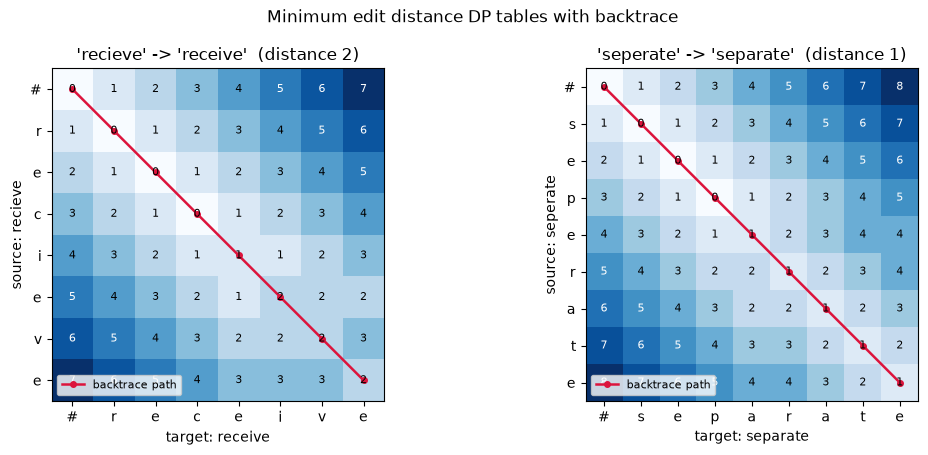

In [8]:
# Activity 4 (heatmaps)  |  Eman Amjad  |  FA23-BAI-013
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, ((w1, w2), (D, path)) in zip(axes, results.items()):
    ax.imshow(D, cmap="Blues")
    for i in range(D.shape[0]):
        for j in range(D.shape[1]):
            ax.text(j, i, D[i, j], ha="center", va="center", fontsize=8,
                    color="white" if D[i, j] > D.max() * 0.6 else "black")
    rows, cols = zip(*path)
    ax.plot(cols, rows, color="crimson", marker="o", markersize=4, linewidth=1.8, label="backtrace path")
    ax.set_xticks(range(len(w2) + 1), ["#"] + list(w2))
    ax.set_yticks(range(len(w1) + 1), ["#"] + list(w1))
    ax.set_xlabel(f"target: {w2}")
    ax.set_ylabel(f"source: {w1}")
    ax.set_title(f"'{w1}' -> '{w2}'  (distance {D[-1, -1]})")
    ax.legend(loc="lower left", fontsize=8)
fig.suptitle("Minimum edit distance DP tables with backtrace")
plt.tight_layout()
plt.show()

**Observations**

- **recieve → receive = 2.** Both strings have 7 letters, so the backtrace stays on the diagonal and makes two substitutions (*i→e*, *e→i*). Standard Levenshtein has no "swap" operation, so the common mistake of swapping two letters costs 2. With `transpositions=True` (Damerau-Levenshtein) NLTK gives 1.
- **seperate → separate = 1**: a single substitution *e→a* at position 4. Every other cell on the path is a match.
- My DP table gives the same final value as `nltk.edit_distance` for both pairs. Filling the tables took 7×7 = 49 and 8×8 = 64 inner-cell updates, which is the O(mn) cost.

**Activity 5** — Assemble one reusable cleaning function that lowercases, removes punctuation, removes stop words and lemmatizes in a single call. Apply it to the whole reviews dataset and report the vocabulary size before and after cleaning together with the percentage reduction.

In [9]:
# Activity 5  |  Eman Amjad  |  FA23-BAI-013
def full_text_pipeline(text, stop_words=spacy_stop_words):
    # lowercase, strip punctuation, collapse whitespace
    text = text.lower().translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    doc = nlp(text)
    # Check the stop list against the surface form AND the lemma, so a word is not dropped
    # for one form and kept for the other (the inconsistency noted in the manual's pitfalls).
    cleaned_tokens = [tok.lemma_.lower() for tok in doc
                      if not tok.is_space
                      and tok.text not in stop_words
                      and tok.lemma_.lower() not in stop_words]
    return " ".join(cleaned_tokens)


raw_words = " ".join(df["text"]).split()
vocab_before = len(set(raw_words))

df["fully_processed"] = df["text"].apply(full_text_pipeline)

cleaned_words = " ".join(df["fully_processed"]).split()
vocab_after = len(set(cleaned_words))
reduction_percentage = (vocab_before - vocab_after) / vocab_before * 100

print(f"Vocabulary Size Before Cleaning: {vocab_before}")
print(f"Vocabulary Size After Cleaning : {vocab_after}")
print(f"Percentage Reduction           : {reduction_percentage:.2f}%")
print(f"Total tokens                   : {len(raw_words)} -> {len(cleaned_words)}")
print("\nSample Output:")
display(df[["review_id", "text", "fully_processed"]].head())

Vocabulary Size Before Cleaning: 130
Vocabulary Size After Cleaning : 75
Percentage Reduction           : 42.31%
Total tokens                   : 169 -> 84

Sample Output:


,review_id,text,fully_processed
0,1,This phone is AMAZING!!! The camera quality is excellent and the battery lasts all day.,phone amazing camera quality excellent battery day
1,2,"Terrible experience. The delivery was late, the box was damaged, and the item didn't...",terrible experience delivery late box damage item work
2,3,"The headphones are okay... not bad, but not great either.",headphone okay bad great
3,4,"Honestly, the battery life is really impressive -- although the charger feels cheap an...",honestly battery life impressive charger feel cheap come box
4,5,I would never buy this again! The screen cracked after two weeks and customer service ...,buy screen crack week customer service help


raw text            130 distinct tokens
+ lowercase         126 distinct tokens
+ no punctuation    121 distinct tokens
+ no stop words      84 distinct tokens
+ lemmatized         75 distinct tokens


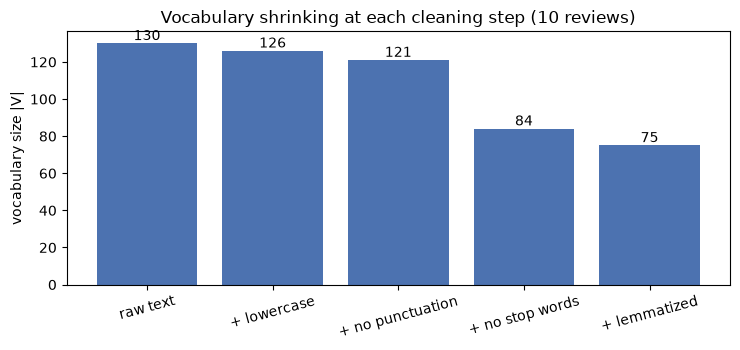

In [10]:
# Activity 5 (vocabulary per stage)  |  Eman Amjad  |  FA23-BAI-013
def vocab_size(texts):
    return len(set(" ".join(texts).split()))


lower = df["text"].str.lower()
no_punct = lower.apply(lambda t: re.sub(r"\s+", " ", t.translate(str.maketrans("", "", string.punctuation))).strip())
no_stop = no_punct.apply(remove_spacy_stopwords)
stages = {
    "raw text": vocab_size(df["text"]),
    "+ lowercase": vocab_size(lower),
    "+ no punctuation": vocab_size(no_punct),
    "+ no stop words": vocab_size(no_stop),
    "+ lemmatized": vocab_size(df["fully_processed"]),
}
for name, size in stages.items():
    print(f"{name:<18} {size:>4} distinct tokens")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = ax.bar(list(stages), list(stages.values()), color="#4C72B0")
ax.bar_label(bars)
ax.set_ylabel("vocabulary size |V|")
ax.set_title("Vocabulary shrinking at each cleaning step (10 reviews)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Observations**

- The full pipeline cuts the vocabulary from **130 to 75** distinct tokens, a **42.31% reduction**, and the token count from 169 to 84.
- Per step: lowercasing removes 4 types, punctuation 5, stop words 37 and lemmatization 9 more (*damaged → damage, cracked → crack, weeks → week*). Stop-word removal does by far the most.
- The pipeline checks both the surface form and the lemma against the stop list. That fixes the inconsistency mentioned in the manual, where a token could be filtered on its raw form while a stop-word lemma got through.
- Review 3 comes out as *headphone okay bad great*. The pipeline suits keyword or topic work but would mislead a sentiment model, as Activity 2 showed.

**Activity 6** — Using `nltk.edit_distance`, compare each word in the misspelled list against every word in the vocabulary list, return the vocabulary word with the smallest distance as the suggested correction, and present the results as a table of misspelled word, suggested correction and distance.

In [11]:
# Activity 6  |  Eman Amjad  |  FA23-BAI-013
vocab_list = ["receive", "definitely", "occurred", "separate", "until",
              "which", "believe", "because", "achieve", "necessary"]
misspelled_words = ["recieve", "definately", "occured", "seperate", "untill", "wich"]

corrections = []
for mis in misspelled_words:
    best_match, min_distance = None, float("inf")   # inf so the first comparison always wins
    distances = {}
    for word in vocab_list:
        dist = nltk.edit_distance(mis, word)
        distances[word] = dist
        if dist < min_distance:                      # strict < keeps the first word on a tie
            min_distance, best_match = dist, word
    runner_up = sorted((d, w) for w, d in distances.items() if w != best_match)[0]
    corrections.append({
        "Misspelled Word": mis,
        "Suggested Correction": best_match,
        "Edit Distance": min_distance,
        "Tied candidates": [w for w, d in distances.items() if d == min_distance and w != best_match],
        "Next best": f"{runner_up[1]} ({runner_up[0]})",
    })

corrections_df = pd.DataFrame(corrections)
display(corrections_df)

,Misspelled Word,Suggested Correction,Edit Distance,Tied candidates,Next best
0,recieve,receive,2,[believe],believe (2)
1,definately,definitely,1,[],separate (6)
2,occured,occurred,1,[],because (5)
3,seperate,separate,1,[],receive (5)
4,untill,until,1,[],which (5)
5,wich,which,1,[],until (5)


**Observations**

- All six misspellings get the intended correction. Five are 1 edit away (*definately, occured, seperate, untill, wich*). *recieve* is 2 edits away because of the swapped letters.
- *recieve* is a **tie**: *receive* and *believe* are both at distance 2. The manual's strict `<` keeps *receive* only because it comes earlier in `vocab_list`. With the list reversed, it would suggest *believe* and never mention the tie. The *Tied candidates* column makes this visible.
- The other five corrections are clear: the next-best word is at least 3 edits further away.

---

# Home Activities

**Home Activity 1** — Clean the support_chats dataset end to end (lowercase, remove stop words, lemmatize) with the reusable cleaning function from the lab, and report the vocabulary size before and after cleaning and the percentage reduction.

In [12]:
# Home Activity 1  |  Eman Amjad  |  FA23-BAI-013
chats = pd.read_csv(DATA_DIR / "support_chats.csv")
chats["cleaned"] = chats["message"].apply(full_text_pipeline)   # same function as Activity 5

chat_vocab_before = set(" ".join(chats["message"]).split())
chat_vocab_after = set(" ".join(chats["cleaned"]).split())
chat_reduction = (len(chat_vocab_before) - len(chat_vocab_after)) / len(chat_vocab_before) * 100

display(chats[["chat_id", "message", "cleaned"]])
print(f"Vocabulary Size Before Cleaning: {len(chat_vocab_before)}")
print(f"Vocabulary Size After Cleaning : {len(chat_vocab_after)}")
print(f"Percentage Reduction           : {chat_reduction:.2f}%")
print(f"Total tokens                   : {len(' '.join(chats['message']).split())} -> "
      f"{len(' '.join(chats['cleaned']).split())}")

typos = ["pakage", "arived", "chek", "crashin", "delievery", "beleive"]
print("\nTypos that survive cleaning untouched:", [t for t in typos if t in chat_vocab_after])

,chat_id,message,cleaned
0,1,"Hi, my pakage still hasnt arived and its been 9 days. Can u pls chek the tracking number?",hi pakage arive 9 day u pls chek tracking number
1,2,"I was charged twice for order #48213. I definately only placed one order, please refun...",charge twice order 48213 definately place order refund extra payment
2,3,The Zentrix app keeps crashin every time I open the settings page after the latest upd...,zentrix app crashin time open setting page late update
3,4,"thx for the quick reply! but the delievery guy left the box at the wrong adress, wich ...",thx quick reply delievery guy leave box wrong adress wich annoying
4,5,I recieved the replacement charger today but the battery is still not charging properly.,recieve replacement charger today battery charge properly
5,6,"hey, i cant login to my acount. i dont beleive i changed my pasword, can u reset it asap?",hey login acount beleive change pasword u reset asap
6,7,An error occured while updating my payment method. The card details were entered corre...,error occur update payment method card detail enter correctly
7,8,"Please send the invoice and the receipt as seperate files, my accounts team needs both.",send invoice receipt seperate file account team need
8,9,ur courier said the parcel was deliverd yesterday but i never got it. pls chek again tmrw,ur courier parcel deliverd yesterday pls chek tmrw
9,10,"Unfortunately the headphones arrived with a broken cable. I would like a replacement, ...",unfortunately headphone arrive broken cable like replacement refund


Vocabulary Size Before Cleaning: 144
Vocabulary Size After Cleaning : 88
Percentage Reduction           : 38.89%
Total tokens                   : 197 -> 103

Typos that survive cleaning untouched: ['pakage', 'chek', 'crashin', 'delievery', 'beleive']


**Observations**

- The support chats shrink from **144 to 88** distinct tokens (**38.89% reduction**), and the token count goes from 197 to 103. That is a little less than the reviews (42.31%), because the chats contain many tokens that no stop list or lemmatizer can merge.
- The typos *pakage, chek, crashin, delievery, beleive* go through cleaning untouched, each as its own vocabulary entry. *arived* and *recieved* are even "lemmatized" into new non-words, *arive* and *recieve*.
- Chat shorthand (*u, pls, thx, ur, tmrw, asap*), the order number *48213* and the product name *zentrix* also survive. Normalization alone can't clean noisy chat text, which is why the spelling correction in Home Activities 3 and 4 is needed.
- *cant, dont, hasnt* do disappear: spaCy splits them into *ca/do/has + nt*, and both halves are stop words.

**Home Activity 2** — From the cleaned support_chats vocabulary, pick 10 words and apply both PorterStemmer and spaCy lemmatization to each. Flag any word where stemming produced something that is not a real English word.

The words are taken from the chats after lowercasing, punctuation removal and stop-word removal but *before* lemmatization; picking from the fully lemmatized vocabulary would make the lemma column trivially equal to the input. A string counts as a real English word if it is in the reference lexicon built in the setup cell (NLTK word list + Brown corpus word forms).

In [13]:
# Home Activity 2  |  Eman Amjad  |  FA23-BAI-013
chat_no_stop = chats["message"].apply(clean_text_basic).apply(remove_spacy_stopwords)
chat_clean_vocab = set(" ".join(chat_no_stop).split())

picked = ["delivery", "arrived", "charged", "replacement", "tracking",
          "battery", "updated", "accounts", "properly", "cancelled"]
assert all(w in chat_clean_vocab for w in picked), "every picked word must come from the chats"

rows = []
for w in picked:
    stem = stemmer.stem(w)
    lemma = nlp(w)[0].lemma_
    rows.append({"word": w, "Porter stem": stem, "spaCy lemma": lemma,
                 "stem is real word": stem in english_lexicon,
                 "lemma is real word": lemma in english_lexicon})
stem_df = pd.DataFrame(rows)
stem_df["flag"] = np.where(stem_df["stem is real word"], "", "NOT A WORD")
display(stem_df)
print(f"Stems that are not English words: {(~stem_df['stem is real word']).sum()} / {len(stem_df)}")
print(f"Lemmas that are not English words: {(~stem_df['lemma is real word']).sum()} / {len(stem_df)}")

,word,Porter stem,spaCy lemma,stem is real word,lemma is real word,flag
0,delivery,deliveri,delivery,False,True,NOT A WORD
1,arrived,arriv,arrive,False,True,NOT A WORD
2,charged,charg,charge,False,True,NOT A WORD
3,replacement,replac,replacement,False,True,NOT A WORD
4,tracking,track,track,True,True,
5,battery,batteri,battery,False,True,NOT A WORD
6,updated,updat,update,False,True,NOT A WORD
7,accounts,account,account,True,True,
8,properly,properli,properly,False,True,NOT A WORD
9,cancelled,cancel,cancel,True,True,


Stems that are not English words: 7 / 10
Lemmas that are not English words: 0 / 10


**Observations**

- **7 of the 10 stems are not English words**: *deliveri, arriv, charg, replac, batteri, updat, properli*. Porter cuts endings like *-y, -ed, -ement, -ly* without checking a dictionary.
- Only *tracking → track*, *accounts → account* and *cancelled → cancel* give real words, and for those three the stem equals the lemma.
- All 10 spaCy lemmas are real words. *replacement* and *delivery* stay as they are, where Porter reduces them to *replac* and *deliveri*.

**Home Activity 3** — Build a spelling-suggestion function using `nltk.edit_distance`. Run it on every misspelled word that can be found in support_chats (e.g. "pakage", "arived", "chek", "beleive", "definately", "crashin", "delievery", "wich", "recieved", "occured", "seperate"), return the closest match from the lab's vocabulary list, and present the corrected version of each chat message.

The lab's ten-word `vocab_list` only covers the classic misspellings (*definitely*, *which*, *believe*, ...), so it is extended with the support team's own terms (*package*, *arrived*, *check*, *delivery*, ...). A word is treated as misspelled when it is not in the reference English lexicon or the vocabulary. Chat shorthand (*u*, *pls*, *thx*) is left for Home Activity 4.

In [14]:
# Home Activity 3  |  Eman Amjad  |  FA23-BAI-013
support_vocab = ["package", "arrived", "check", "crashing", "delivery", "delivered", "received",
                 "address", "account", "password", "tomorrow", "tracking", "refund", "replacement",
                 "order", "payment", "courier", "parcel", "charger", "battery", "settings", "update",
                 "updating", "invoice", "receipt", "login", "headphones", "subscription"]
suggestion_vocab = list(dict.fromkeys(vocab_list + support_vocab))     # lab list first, no duplicates
known_words = english_lexicon | set(suggestion_vocab) | nltk_stop_words

# chat shorthand is handled by a lookup in Home Activity 4, not by edit distance
INFORMAL = {"u": "you", "ur": "your", "pls": "please", "plz": "please", "thx": "thanks",
            "tmrw": "tomorrow", "asap": "as soon as possible", "i": "I", "im": "I'm",
            "dont": "don't", "cant": "can't", "hasnt": "hasn't", "its": "it's"}


def common_prefix(a, b):
    k = 0
    while k < min(len(a), len(b)) and a[k] == b[k]:
        k += 1
    return k


def suggest(word, vocab=suggestion_vocab, max_distance=2):
    """Closest vocabulary word by Levenshtein distance.
    Returns (suggestion or None, distance, all tied candidates)."""
    word = word.lower()
    dists = [(nltk.edit_distance(word, v), v) for v in vocab]
    best = min(d for d, _ in dists)
    tied = [v for d, v in dists if d == best]
    # Tie-break instead of silently keeping the first word in the list:
    # 1) fewer edits when a swap of two neighbouring letters counts as one (typical typo),
    # 2) longer shared beginning (people rarely mistype the first letters),
    # 3) longer shared ending.
    choice = min(tied, key=lambda v: (nltk.edit_distance(word, v, transpositions=True),
                                      -common_prefix(word, v),
                                      -common_prefix(word[::-1], v[::-1])))
    return (choice if best <= max_distance else None), best, tied


WORD_RE = re.compile(r"[A-Za-z]+")


def find_misspellings(text):
    found = []
    for w in WORD_RE.findall(text):
        lw = w.lower()
        if lw not in known_words and lw not in INFORMAL:
            found.append(lw)
    return found


def match_case(original, replacement):
    return replacement.capitalize() if original[0].isupper() else replacement


def correct_spelling(text):
    def fix(m):
        w = m.group(0)
        if w.lower() in known_words or w.lower() in INFORMAL:
            return w
        sug, _, _ = suggest(w)
        return match_case(w, sug) if sug else w      # no close match: leave it (e.g. a product name)
    return WORD_RE.sub(fix, text)


misspelled_in_chats = list(dict.fromkeys(w for msg in chats["message"] for w in find_misspellings(msg)))
rows = []
for w in misspelled_in_chats:
    sug, dist, tied = suggest(w)
    lab_only, lab_d, _ = suggest(w, vocab=vocab_list, max_distance=99)
    rows.append({"misspelled": w, "suggestion": sug if sug else "(no change)", "distance": dist,
                 "tied candidates": tied if len(tied) > 1 else "",
                 "lab vocab_list only": f"{lab_only} ({lab_d})"})
spell_df = pd.DataFrame(rows)
print(f"Misspelled words found in the chats: {len(misspelled_in_chats)}")
display(spell_df)

chats["spell_corrected"] = chats["message"].apply(correct_spelling)
for _, r in chats.iterrows():
    print(f"[{r.chat_id:>2}] original : {r.message}")
    print(f"     corrected: {r.spell_corrected}\n")

Misspelled words found in the chats: 16


,misspelled,suggestion,distance,tied candidates,lab vocab_list only
0,pakage,package,1,,separate (4)
1,arived,arrived,1,,achieve (4)
2,chek,check,1,,which (4)
3,definately,definitely,1,,definitely (1)
4,zentrix,(no change),4,,until (4)
5,crashin,crashing,1,,receive (6)
6,delievery,delivery,1,,believe (3)
7,adress,address,1,,achieve (5)
8,wich,which,1,,which (1)
9,recieved,received,2,,receive (3)


[ 1] original : Hi, my pakage still hasnt arived and its been 9 days. Can u pls chek the tracking number?
     corrected: Hi, my package still hasnt arrived and its been 9 days. Can u pls check the tracking number?

[ 2] original : I was charged twice for order #48213. I definately only placed one order, please refund the extra payment.
     corrected: I was charged twice for order #48213. I definitely only placed one order, please refund the extra payment.

[ 3] original : The Zentrix app keeps crashin every time I open the settings page after the latest update.
     corrected: The Zentrix app keeps crashing every time I open the settings page after the latest update.

[ 4] original : thx for the quick reply! but the delievery guy left the box at the wrong adress, wich is really annoying
     corrected: thx for the quick reply! but the delivery guy left the box at the wrong address, which is really annoying

[ 5] original : I recieved the replacement charger today but the battery is s

**Observations**

- **16 unknown words** were found. 15 are real misspellings and all 15 are corrected. The 16th is the product name *Zentrix*, whose nearest vocabulary word is 4 edits away. That is above the threshold of 2, so it is correctly left alone.
- The last column shows why the lab's 10-word list had to be extended: with that list alone, *pakage* becomes *separate* and *chek* becomes *which*. Edit distance always returns *something*, so the vocabulary has to contain the right answer.
- **Ties** came up twice. *beleive* is at distance 2 from both *receive* and *believe*. The swap-aware tie-break picks *believe* (1 Damerau edit against 2); the strict `<` from Activity 6 would have picked *receive* and turned message 6 into nonsense. *deliverd* is 1 edit from both *delivery* and *delivered*, and the shared ending *-d* selects *delivered*.
- In the corrected messages every spelling error is fixed. Informal words (*u, pls, thx, ur, tmrw*) are still there; Home Activity 4 handles them.

**Home Activity 4** — Simulate autocorrect for a live support chat tool: for messages 1, 4, 6 and 9, identify the misspelled or informal words, correct them with the edit-distance suggestion function, and produce the fully corrected message as the system would show it to a support agent.

In [15]:
# Home Activity 4  |  Eman Amjad  |  FA23-BAI-013
# First: what pure edit distance would do with chat shorthand
probe = ["u", "ur", "pls", "thx", "tmrw", "asap", "hasnt"]
print("Edit-distance-only suggestions for informal words:")
for w in probe:
    sug, d, tied = suggest(w, max_distance=99)
    print(f"  {w:<6} -> {sug:<12} (distance {d})   intended: {INFORMAL[w]}")


def autocorrect(text):
    """Informal lookup first, then edit-distance spelling correction, then sentence capitals."""
    changes = []

    def fix(m):
        w, lw = m.group(0), m.group(0).lower()
        if lw in INFORMAL and INFORMAL[lw] != w:
            changes.append((w, INFORMAL[lw], "informal"))
            return INFORMAL[lw]
        if lw not in known_words:
            sug, d, _ = suggest(lw)
            if sug:
                changes.append((w, match_case(w, sug), f"spelling, distance {d}"))
                return match_case(w, sug)
        return w

    fixed = WORD_RE.sub(fix, text)
    # capitalise the first letter of every sentence
    fixed = re.sub(r"(^|[.!?]\s+)([a-z])", lambda m: m.group(1) + m.group(2).upper(), fixed)
    if fixed[-1] not in ".!?":
        fixed += "."
    return fixed, changes


agent_rows = []
for cid in (1, 4, 6, 9):
    msg = chats.loc[chats.chat_id == cid, "message"].item()
    fixed, changes = autocorrect(msg)
    print(f"\n=== Chat {cid} ===")
    print(f"Customer typed : {msg}")
    print(f"Agent sees     : {fixed}")
    for old, new, why in changes:
        print(f"   {old:>10} -> {new:<22} [{why}]")
    agent_rows.append({"chat_id": cid, "corrections": len(changes), "shown to agent": fixed})

display(pd.DataFrame(agent_rows))

Edit-distance-only suggestions for informal words:
  u      -> until        (distance 4)   intended: you
  ur     -> until        (distance 4)   intended: your
  pls    -> parcel       (distance 5)   intended: please
  thx    -> until        (distance 4)   intended: thanks
  tmrw   -> tomorrow     (distance 4)   intended: tomorrow
  asap   -> until        (distance 5)   intended: as soon as possible
  hasnt  -> payment      (distance 4)   intended: hasn't



=== Chat 1 ===
Customer typed : Hi, my pakage still hasnt arived and its been 9 days. Can u pls chek the tracking number?
Agent sees     : Hi, my package still hasn't arrived and it's been 9 days. Can you please check the tracking number?
       pakage -> package                [spelling, distance 1]
        hasnt -> hasn't                 [informal]
       arived -> arrived                [spelling, distance 1]
          its -> it's                   [informal]
            u -> you                    [informal]
          pls -> please                 [informal]
         chek -> check                  [spelling, distance 1]

=== Chat 4 ===
Customer typed : thx for the quick reply! but the delievery guy left the box at the wrong adress, wich is really annoying
Agent sees     : Thanks for the quick reply! But the delivery guy left the box at the wrong address, which is really annoying.
          thx -> thanks                 [informal]
    delievery -> delivery               [spelling, 

,chat_id,corrections,shown to agent
0,1,7,"Hi, my package still hasn't arrived and it's been 9 days. Can you please check the tra..."
1,4,4,"Thanks for the quick reply! But the delivery guy left the box at the wrong address, wh..."
2,6,10,"Hey, I can't login to my account. I don't believe I changed my password, can you reset..."
3,9,6,Your courier said the parcel was delivered yesterday but I never got it. Please check ...


**Observations**

- Edit distance on its own can't handle chat shorthand. *u, pls, thx* and *asap* all map to *until*, and *ur* maps to *order*, all 4–5 edits away. Abbreviations remove too many letters, so they end up closest to whatever short word happens to be in the vocabulary. The autocorrect therefore checks a small informal-word table first and only sends real unknown words to the edit-distance function.
- The four messages need 7, 4, 10 and 6 corrections. The agent receives grammatical sentences with capitalized sentence starts, *I* instead of *i*, apostrophes restored (*hasn't, can't, don't*) and every typo fixed.
- Limitations: *its → it's* is right in chat 1 but would be wrong for a possessive *its*. Context-free rules can't tell them apart, and a noisy-channel model with a language model would be needed for that. *login* is accepted as written, since it is in the support vocabulary.

---

### Lab 04 complete

6 in-lab activities and 4 home activities — submitted by Eman Amjad (FA23-BAI-013).